# Chart 2: Inflation-adjusted average U.S. regular retail gasoline price, by administration

Article: <https://www.dailysignal.com/2026/09/30/real-story-gas-prices/> (Sanjai Bhagat, The Daily Signal, 30 Sep 2026).

Replicates the article's second chart: the same EIA gasoline prices as chart 1, expressed in August 2026 dollars. Cited sources: www.eia.gov (series `EMM_EPMR_PTE_NUS_DPG`) and www.bls.gov. The article does not name the CPI index; CPI-U All Items, U.S. city average, not seasonally adjusted (`CUUR0000SA0`) is the variant that reproduces its figures.

Shared pieces live in two modules: `fetch_data.py` checks whether the local data is current and downloads it if not;
`charts.py` holds the styling, the administration windows and the chart helpers. The rendered PNG is written to `output/`.

---

# Part 1 — The article's chart

A straight replication of the Daily Signal chart: same series, same windows, same base month, compared against the article's published figures.


## Data currency check

Only the sources this chart needs are checked. Stale or missing copies are downloaded; current ones are left alone.

In [1]:
import fetch_data

statuses = fetch_data.refresh(['eia_gasoline', 'bls_cpi'])

eia_gasoline   current    latest=2026-09-01 fetched=2026-10-06T20:52:21+00:00
bls_cpi        current    latest=2026-08-01 fetched=2026-10-06T20:52:22+00:00


## Load the data

In [2]:
import datetime as dt
import numpy as np
import polars as pl
import charts

gas = fetch_data.load("eia_gasoline")  # date, price_usd_per_gal
cpi = fetch_data.load("bls_cpi")       # date, cpi_u_nsa, note
print(f"gas {gas['date'].min()} .. {gas['date'].max()}  ({gas.height} months)")
print(f"cpi {cpi['date'].min()} .. {cpi['date'].max()}  ({cpi.height} months, {cpi['cpi_u_nsa'].null_count()} unpublished)")
cpi.filter(pl.col("cpi_u_nsa").is_null())

gas 1990-09-01 .. 2026-09-01  (431 months)
cpi 1990-01-01 .. 2026-08-01  (440 months, 1 unpublished)


date,cpi_u_nsa,note
date,f64,str
2025-10-01,null,"""Data unavailable due to the 20…"


## Fill the unpublished month

BLS did not publish an October 2025 CPI because of the lapse in appropriations. It is filled by linear interpolation
(`numpy.interp`) between September and November 2025 so the month still contributes to the Trump 2.0 average.

In [3]:
known = cpi.filter(pl.col("cpi_u_nsa").is_not_null())
cpi_filled = cpi.with_columns(
    pl.Series("cpi_filled", np.interp(
        cpi["date"].dt.epoch("d").to_numpy(),
        known["date"].dt.epoch("d").to_numpy(),
        known["cpi_u_nsa"].to_numpy(),
    ))
)
cpi_filled.filter(pl.col("date").is_between(pl.date(2025, 9, 1), pl.date(2025, 11, 1)))

date,cpi_u_nsa,note,cpi_filled
date,f64,str,f64
2025-09-01,324.8,null,324.8
2025-10-01,null,"""Data unavailable due to the 20…",324.466557
2025-11-01,324.122,null,324.122


## Administration windows and base month

Same windows as chart 1. Prices are restated in the dollars of the last month of the Trump 2.0 window (August 2026 in the article).
Set `EXTEND_TO_LATEST = True` to use the newest month that has both a gasoline price and a CPI value.

In [4]:
EXTEND_TO_LATEST = False

admins = dict(charts.ADMINS)
if EXTEND_TO_LATEST:
    last = min(gas["date"].max(), known["date"].max())
    admins["Trump 2.0"] = (admins["Trump 2.0"][0], last)
BASE_MONTH = admins["Trump 2.0"][1]
base_cpi = cpi_filled.filter(pl.col("date") == BASE_MONTH)["cpi_filled"][0]
print(BASE_MONTH.strftime("%B %Y"), "CPI-U =", base_cpi)

August 2026 CPI-U = 334.98


## Chart

Each month's price is multiplied by `CPI(base month) / CPI(month)` before averaging over the window.

administration,recomputed,article
str,f64,f64
"""Obama""",4.33,4.33
"""Trump 1.0""",3.29,3.29
"""Biden""",3.91,3.91
"""Trump 2.0""",3.45,3.45


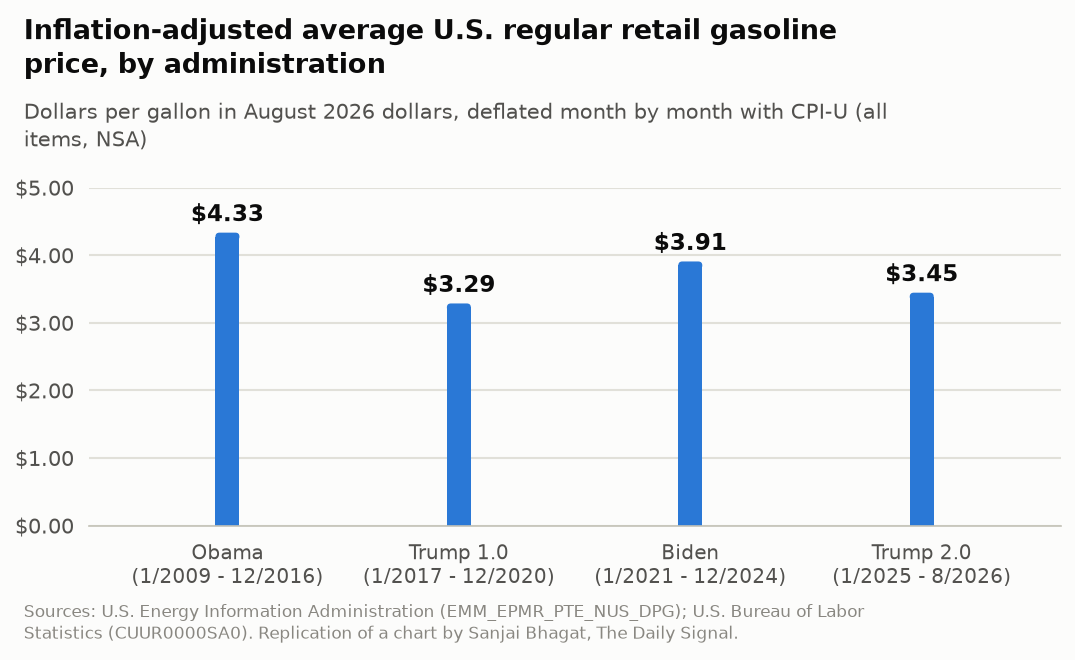

In [5]:
real = (
    gas.join(cpi_filled.select("date", "cpi_filled"), on="date", how="inner")
       .with_columns((pl.col("price_usd_per_gal") * base_cpi / pl.col("cpi_filled")).alias("real_price"))
)
real_means = charts.period_mean(real, "real_price", admins)
ARTICLE = [4.33, 3.29, 3.91, 3.45]

charts.bar_chart(
    charts.admin_labels(admins), real_means,
    title="Inflation-adjusted average U.S. regular retail gasoline price, by administration",
    subtitle=f"Dollars per gallon in {BASE_MONTH.strftime('%B %Y')} dollars, deflated month by month with CPI-U (all items, NSA)",
    source="Sources: U.S. Energy Information Administration (EMM_EPMR_PTE_NUS_DPG); U.S. Bureau of Labor Statistics (CUUR0000SA0). Replication of a chart by Sanjai Bhagat, The Daily Signal.",
    fmt=lambda v: f"${v:,.2f}", ymax=5.0, ystep=1.0, fname="02_gas_price_real.png",
)
charts.compare(admins, real_means, ARTICLE)

## Notes

With the October 2025 gap interpolated, all four figures match the article exactly. Deflating with the seasonally adjusted index
(`CUSR0000SA0`) instead lands a cent or two lower in every window.

---

# Part 2 — My analysis

Everything above reproduces the article as published. This section is my own analysis of the same data and is not part of the article.


## Weekly real price, segmented from the base month

The finest grain available from the sources the article cites:

- **Price.** EIA publishes the same series weekly (`EMM_EPMR_PTE_NUS_DPG`, weekly frequency): one observation every Monday since August 1990. There is no daily series from EIA.
- **Inflation.** CPI-U is monthly only. Each weekly price is deflated by the CPI of the calendar month it falls in (October 2025 interpolated as in Part 1).

So the most granular combination is a weekly price in August 2026 dollars. The time axis is cut into **7-day segments anchored at midnight on
the first day of the base month** (1 August 2026 00:00), extending backwards and forwards from there, rather than at the EIA's Monday
dates or at calendar months. Every observation is assigned to the segment containing it and segments are averaged; with one Monday
in each 7-day segment that average is just the observation itself, but the code does not assume so.

The series stops at the last segment whose month has a published CPI, so it ends in August 2026 even though EIA has September prices.
Reuses `cpi_filled`, `base_cpi`, `BASE_MONTH` and `admins` from Part 1. `SERIES_START` trims the plot; the data run from 1990.

**Term-start markers.** Each four-year term from 20 January 2009 is marked at the EIA observation on 20 January or, when that is not a
Monday, the first Monday before it, with the date and the value there. The same markers are drawn on every chart in this section.


In [6]:
fetch_data.refresh(["eia_gasoline_weekly"])
weekly = fetch_data.load("eia_gasoline_weekly")  # date (Monday), price_usd_per_gal

SEGMENT = dt.timedelta(days=7)
ANCHOR = dt.datetime.combine(BASE_MONTH, dt.time.min)  # midnight, first day of the base month
SERIES_START = admins["Obama"][0]

weekly_real = (
    weekly.with_columns(pl.col("date").dt.truncate("1mo").alias("month"))
          .join(cpi_filled.select(pl.col("date").alias("month"), "cpi_filled"), on="month", how="inner")
          .with_columns((pl.col("price_usd_per_gal") * base_cpi / pl.col("cpi_filled")).alias("real_price"))
          .with_columns(
              ((pl.col("date").cast(pl.Datetime) - pl.lit(ANCHOR)).dt.total_days() // SEGMENT.days).alias("segment")
          )
          .with_columns((pl.lit(ANCHOR) + pl.duration(days=pl.col("segment") * SEGMENT.days)).alias("segment_start"))
)
segments = (
    weekly_real.group_by("segment_start")
               .agg(pl.col("real_price").mean(), pl.len().alias("observations"))
               .sort("segment_start")
)
print(f"{segments.height} segments of {SEGMENT.days} days, {segments['segment_start'].min()} .. {segments['segment_start'].max()}, "
      f"observations per segment: {segments['observations'].unique().to_list()}")
segments.tail(3)


eia_gasoline_weekly current    latest=2026-10-05 fetched=2026-10-06T21:40:11+00:00
1875 segments of 7 days, 1990-08-18 00:00:00 .. 2026-08-29 00:00:00, observations per segment: [1]


segment_start,real_price,observations
datetime[μs],f64,u32
2026-08-15 00:00:00,4.049,1
2026-08-22 00:00:00,4.085,1
2026-08-29 00:00:00,4.071,1


### Trend curve

A *line of best fit* is the straight line that minimises the squared distance to the data (least-squares regression). The curved
version is **LOESS** (locally estimated scatterplot smoothing): at every point a small weighted regression is fitted to the nearest
fraction of the data, with nearby points weighted most, and the fitted value there is the trend. Unlike a moving average it does not
lag and does not flatten peaks as much, and unlike a single polynomial it follows local bends. `LOESS_WEEKS` is the number of weekly
points in each local fit (wider is smoother; 209 is four years); `LOESS_DEGREE` is the local polynomial (1 linear, 2 quadratic). Chart 1 draws the
curve itself; chart 2 draws its derivative (the slope of the chart 1 curve, as a centred difference), so chart 2's trend crosses zero
exactly where chart 1's trend peaks or bottoms out.


In [7]:
LOESS_WEEKS = 209   # width of each local fit in weeks (209 ≈ 4 years)
LOESS_DEGREE = 2    # local polynomial degree


def loess(x, y, weeks: int = LOESS_WEEKS, degree: int = LOESS_DEGREE) -> np.ndarray:
    """LOESS smoother: tricube-weighted local polynomial regression, evaluated at every x (one point per week)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    m = min(max(weeks, degree + 2), n)  # points per local fit
    out = np.empty(n)
    for i in range(n):
        d = np.abs(x - x[i])
        h = np.partition(d, m - 1)[m - 1]  # distance to the m-th nearest point
        w = np.clip(1 - (d / h) ** 3, 0, 1) ** 3  # tricube weights
        use = w > 0
        coef = np.polyfit(x[use] - x[i], y[use], degree, w=np.sqrt(w[use]))
        out[i] = coef[-1]  # value of the local polynomial at x[i]
    return out


def days(dates) -> np.ndarray:
    """Dates as float days, for fitting and differentiating."""
    return (np.asarray(dates, dtype="datetime64[D]") - np.datetime64("1970-01-01", "D")).astype(float)


def loess_label() -> str:
    return f"LOESS trend ({LOESS_WEEKS}-week fits ≈ {LOESS_WEEKS / 52.18:.1f} yr, local {'linear' if LOESS_DEGREE == 1 else 'quadratic'})"


def trend_overlay(ax, dates, trend, *, raw_label: str, trend_label: str) -> None:
    """Draw `trend` over the series already on `ax` and add a two-entry legend."""
    ax.lines[0].set_label(raw_label)
    ax.plot(np.asarray(dates), trend, color=charts.INK2, lw=2, zorder=3, label=trend_label)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=2, fontsize=8.5, labelcolor=charts.INK2,
              handlelength=1.6, columnspacing=1.5, frameon=True, facecolor=charts.SURFACE, edgecolor="none", framealpha=1)


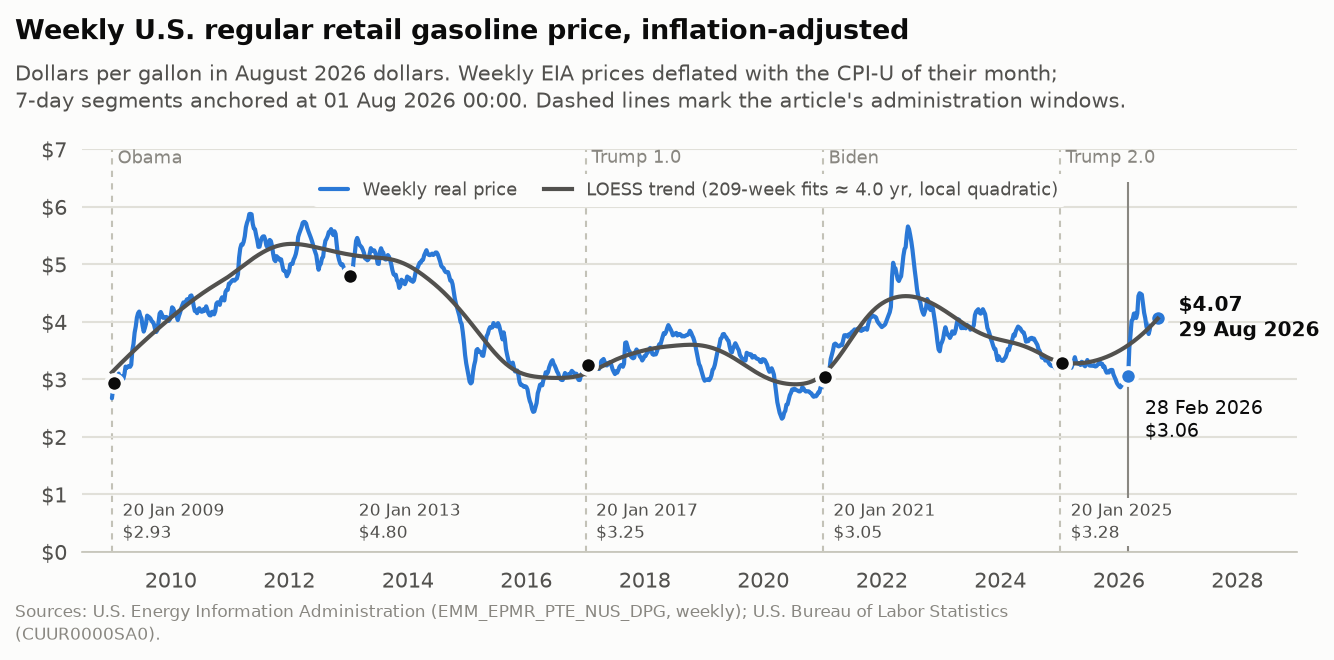

In [8]:
DATE_MARKS = {"28 Feb 2026": dt.date(2026, 2, 28)}
TERM_STARTS = [dt.date(y, 1, 20) for y in range(2009, 2026, 4)]
TERM_OBS = pl.DataFrame({"term_start": TERM_STARTS}).with_columns(  # 20 January, or the first Monday before it
    (pl.col("term_start") - pl.duration(days=pl.col("term_start").dt.weekday() - 1)).alias("date")
)


def term_markers(ax, df: pl.DataFrame, col: str, fmt) -> pl.DataFrame:
    """Ringed dot on `col` at each term-start observation, with date and value labelled along the bottom."""
    rows = TERM_OBS.join(df.select("date", "segment_start", col), on="date", how="left")
    y0 = ax.get_ylim()[0]
    for r in rows.iter_rows(named=True):
        ax.plot([r["segment_start"]], [r[col]], marker="o", ms=8, mfc=charts.INK, mec=charts.SURFACE, mew=2, lw=0, zorder=4)
        ax.annotate(f"{r['term_start']:%-d %b %Y}\n{fmt(r[col])}", (r["segment_start"], y0), xytext=(4, 4),
                    textcoords="offset points", ha="left", va="bottom", fontsize=8, color=charts.INK2, linespacing=1.3,
                    bbox=dict(boxstyle="square,pad=0.15", fc=charts.SURFACE, ec="none"), zorder=5)
    return rows


plot = segments.filter(pl.col("segment_start") >= dt.datetime.combine(SERIES_START, dt.time.min))
last = plot.row(-1, named=True)

fig = charts.line_chart(
    plot["segment_start"].to_numpy(), plot["real_price"],
    title="Weekly U.S. regular retail gasoline price, inflation-adjusted",
    subtitle=(f"Dollars per gallon in {BASE_MONTH.strftime('%B %Y')} dollars. Weekly EIA prices deflated with the CPI-U of their month; "
              f"{SEGMENT.days}-day segments anchored at {ANCHOR:%d %b %Y} 00:00. Dashed lines mark the article's administration windows."),
    source="Sources: U.S. Energy Information Administration (EMM_EPMR_PTE_NUS_DPG, weekly); U.S. Bureau of Labor Statistics (CUUR0000SA0).",
    ylim=(0, 7), ystep=1, yfmt=lambda v: f"${v:,.0f}",
    end_label=f"${last['real_price']:,.2f}\n{last['segment_start']:%-d %b %Y}",
    year_step=2, xpad_years=3, bands=admins,
    marks=DATE_MARKS, mark_fmt=lambda v: f"${v:,.2f}",
    fname=None,
)

trend_x = plot["segment_start"].to_numpy()
trend = loess(days(trend_x), plot["real_price"])  # reused by chart 2
trend_overlay(fig.axes[0], trend_x, trend, raw_label="Weekly real price", trend_label=loess_label())
term_markers(fig.axes[0], weekly_real, "real_price", lambda v: f"${v:,.2f}")
fig.savefig(charts.OUT / "02b_gas_price_real_weekly.png")


## Rate of change of the price trend

The derivative of chart 1's LOESS trend: how fast the trend was rising or falling at each point, in cents per gallon per week,
taken as a centred difference along the fitted curve. Positive means the trend is rising, negative falling, and it crosses zero exactly
where the chart 1 curve peaks or bottoms out. Its own slope is chart 1's curvature: falling while positive means a rise that is slowing
toward a peak, rising while negative means a decline that is easing toward a trough. The raw week-to-week derivative of the price is
too noisy to read and is not shown.


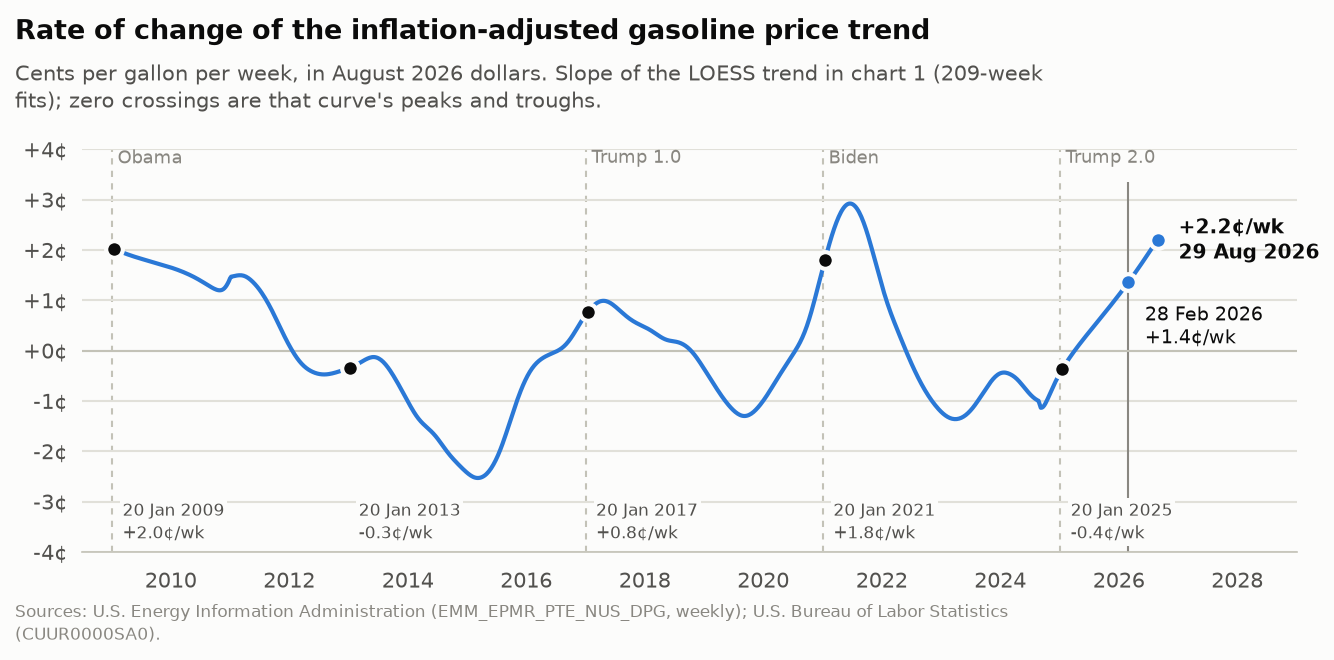

In [9]:
trend_rate = (
    pl.DataFrame({"segment_start": trend_x, "cents_per_week": np.gradient(trend, days(trend_x)) * 7 * 100})
      .join(weekly_real.select("date", "segment_start"), on="segment_start", how="left")
      .sort("segment_start")
)
last = trend_rate.row(-1, named=True)
lim = float(np.ceil(trend_rate["cents_per_week"].abs().max())) + 1  # symmetric limit, whole cents, with headroom for labels

fig = charts.line_chart(
    trend_rate["segment_start"].to_numpy(), trend_rate["cents_per_week"],
    title="Rate of change of the inflation-adjusted gasoline price trend",
    subtitle=(f"Cents per gallon per week, in {BASE_MONTH.strftime('%B %Y')} dollars. Slope of the LOESS trend in chart 1 "
              f"({LOESS_WEEKS}-week fits); zero crossings are that curve's peaks and troughs."),
    source="Sources: U.S. Energy Information Administration (EMM_EPMR_PTE_NUS_DPG, weekly); U.S. Bureau of Labor Statistics (CUUR0000SA0).",
    ylim=(-lim, lim), ystep=1, yfmt=lambda v: f"{v:+.0f}¢",
    end_label=f"{last['cents_per_week']:+.1f}¢/wk\n{last['segment_start']:%-d %b %Y}",
    year_step=2, xpad_years=3, bands=admins,
    marks=DATE_MARKS, mark_fmt=lambda v: f"{v:+.1f}¢/wk",
    fname=None,
)
ax = fig.axes[0]
ax.axhline(0, color=charts.BASELINE, lw=1, zorder=0.7)
term_markers(ax, trend_rate, "cents_per_week", lambda v: f"{v:+.1f}¢/wk")
fig.savefig(charts.OUT / "02c_gas_price_real_weekly_rate.png")


## One-year segments beginning 28 February

The same weekly real prices, grouped into one-year segments that each begin on 28 February and end on the following 27 February,
and averaged within each segment. `YEAR_SEGMENT_DAY` sets the boundary; the last segment is partial and is marked with an asterisk.


In [10]:
YEAR_SEGMENT_DAY = (2, 28)  # (month, day) on which every one-year segment begins


def year_segment_start(d: pl.Expr) -> pl.Expr:
    """First day of the one-year segment containing date `d`."""
    m, dd = YEAR_SEGMENT_DAY
    before_boundary = (d.dt.month() < m) | ((d.dt.month() == m) & (d.dt.day() < dd))
    year = d.dt.year() - before_boundary.cast(pl.Int32)
    return pl.date(year, m, dd)


yearly = (
    segments.with_columns(year_segment_start(pl.col("segment_start").dt.date()).alias("year_start"))
            .filter(pl.col("year_start") >= SERIES_START)
            .group_by("year_start")
            .agg(pl.col("real_price").mean(), pl.col("segment_start").max().dt.date().alias("last_segment"), pl.len().alias("weeks"))
            .sort("year_start")
            .with_columns((pl.col("year_start").dt.offset_by("1y") - pl.duration(days=1)).alias("year_end"))
            .with_columns((pl.col("last_segment") < pl.col("year_end") - pl.duration(days=7)).alias("partial"))
)
yearly


year_start,real_price,last_segment,weeks,year_end,partial
date,f64,date,u32,date,bool
2009-02-28,3.860381,2010-02-27,53,2010-02-27,false
2010-02-28,4.382053,2011-02-26,52,2011-02-27,false
2011-02-28,5.30097,2012-02-25,52,2012-02-27,false
2012-02-28,5.273773,2013-02-23,52,2013-02-27,false
2013-02-28,4.993685,2014-02-22,52,2014-02-27,false
…,…,…,…,…,…
2022-02-28,4.472672,2023-02-25,52,2023-02-27,false
2023-02-28,3.806426,2024-02-24,52,2024-02-27,false
2024-02-28,3.509868,2025-02-22,52,2025-02-27,false


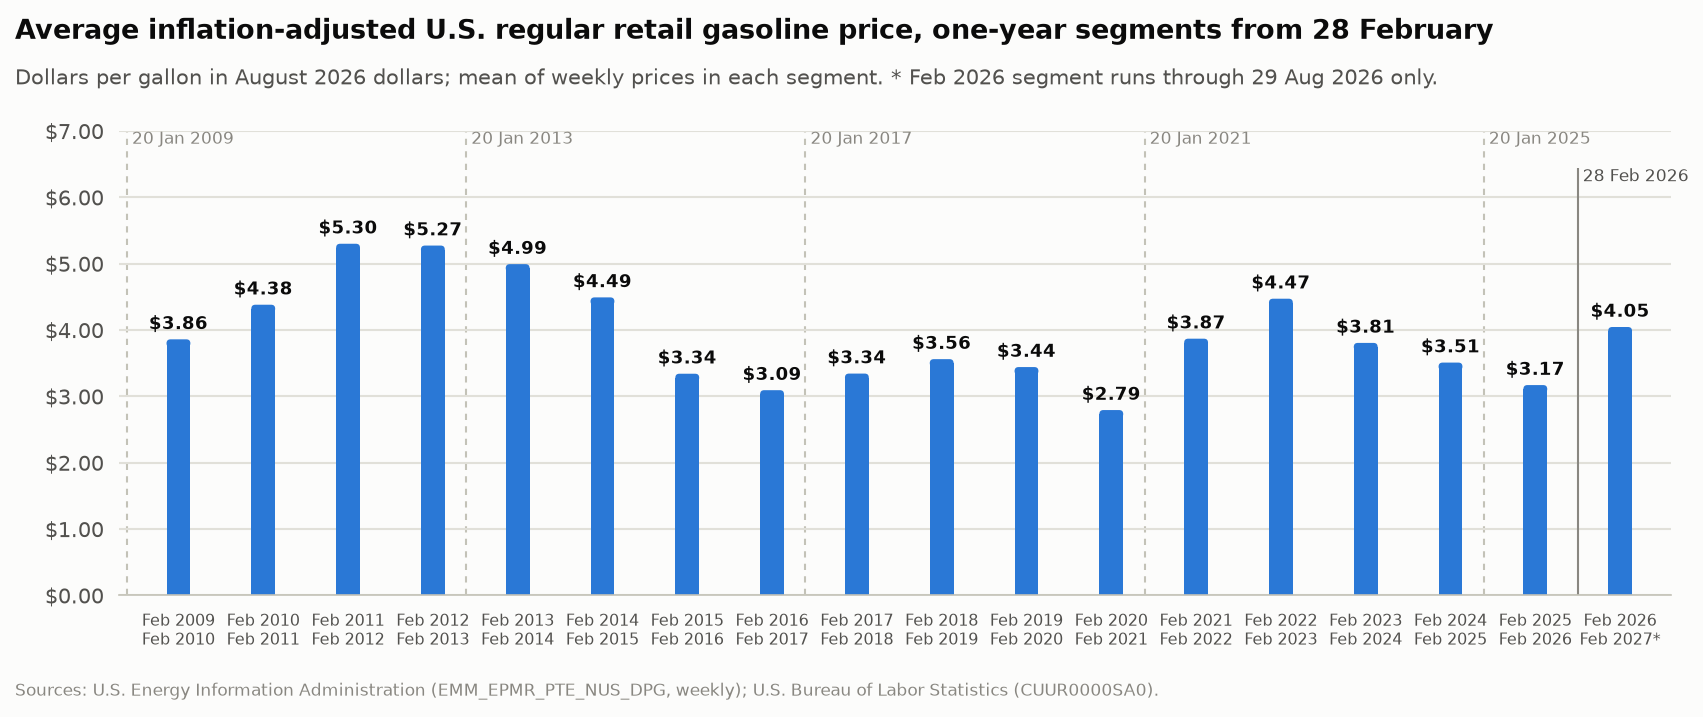

In [11]:
labels = [f"{r['year_start']:%b %Y}\n{r['year_end']:%b %Y}{'*' if r['partial'] else ''}" for r in yearly.iter_rows(named=True)]
partial = yearly.filter("partial")
note = (f" * {partial['year_start'][0]:%b %Y} segment runs through {partial['last_segment'][0]:%-d %b %Y} only."
        if partial.height else "")

fig = charts.bar_chart(
    labels, yearly["real_price"].to_list(),
    title="Average inflation-adjusted U.S. regular retail gasoline price, one-year segments from 28 February",
    subtitle=f"Dollars per gallon in {BASE_MONTH.strftime('%B %Y')} dollars; mean of weekly prices in each segment.{note}",
    source="Sources: U.S. Energy Information Administration (EMM_EPMR_PTE_NUS_DPG, weekly); U.S. Bureau of Labor Statistics (CUUR0000SA0).",
    fmt=lambda v: f"${v:,.2f}", ymax=7.0, ystep=1.0, figsize=(11.5, 4.8), label_size=7.5, value_size=8.5,
    fname=None,
)

# --- same term-start and date markers as the weekly chart ---------------------------------------
starts = yearly["year_start"].to_list()


def segment_x(d: dt.date) -> float:
    """Categorical x of date `d`: its segment's bar index, offset by its fraction of the way through the segment."""
    i = max((k for k, s in enumerate(starts) if s <= d), default=0)
    length = (starts[i].replace(year=starts[i].year + 1) - starts[i]).days
    return i - 0.5 + (d - starts[i]).days / length


ax = fig.axes[0]
ax.set_xlim(min(ax.get_xlim()[0], segment_x(TERM_STARTS[0]) - 0.1), ax.get_xlim()[1])
ymax = ax.get_ylim()[1]
for t in TERM_STARTS:
    ax.axvline(segment_x(t), color=charts.BASELINE, lw=1, ls=(0, (3, 3)), zorder=0.5)
    ax.text(segment_x(t), ymax, f" {t:%-d %b %Y}", ha="left", va="top", fontsize=8, color=charts.MUTED)
for label, d in DATE_MARKS.items():
    ax.vlines(segment_x(d), 0, 0.92 * ymax, color=charts.MUTED, lw=1, zorder=0.6)
    ax.text(segment_x(d), 0.92 * ymax, f" {label}", ha="left", va="top", fontsize=8, color=charts.INK2)
fig.savefig(charts.OUT / "02d_gas_price_real_yearly_feb28.png")
